# 01 — Behavior Cloning

In the previous notebook we constructed a scripted expert and collected
demonstrations of two valid strategies: going left or right around an obstacle.

We now want to learn a policy from those demonstrations.

Behavior Cloning (BC) treats imitation learning as supervised learning:

$$
(o_t, a_t) \sim \mathcal{D}
$$

and learns a policy

$$
\hat{a}_t = \pi_\theta(o_t)
$$

by minimizing the difference between the predicted action and the expert action.

We will start with the simplest possible approach: a deterministic MLP trained
with Mean Squared Error (MSE).

The main question of this notebook is:

> Does a low supervised-learning error necessarily imply a good policy?

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np

In [21]:
from robot_learning_playground.point_robot import (
    collect_demonstrations,
    rollout,
)

# Collect demonstrations from the expert policy
demonstrations = collect_demonstrations(
    n_episodes=200,
    seed=42,
)

print("Number of demonstrations collected:", len(demonstrations))
for i, demo in enumerate(demonstrations[:3]):
    print(f"Demonstration {i}:")
    print("  Observations shape:", demo["observations"].shape)
    print("  Actions shape:", demo["actions"].shape)
    print("  Positions shape:", demo["positions"].shape)

Number of demonstrations collected: 200
Demonstration 0:
  Observations shape: (25, 4)
  Actions shape: (25, 2)
  Positions shape: (26, 2)
Demonstration 1:
  Observations shape: (26, 4)
  Actions shape: (26, 2)
  Positions shape: (27, 2)
Demonstration 2:
  Observations shape: (26, 4)
  Actions shape: (26, 2)
  Positions shape: (27, 2)


For a first simple Behavior Cloning (BC) we ignore the temporal structure anc consider all ($o_i$, $a_i$) pairs as supervised samples

In [22]:
# Concatenate all observations and actions
observations = np.concatenate([
    demo["observations"]
    for demo in demonstrations
])

actions = np.concatenate([
    demo["actions"]
    for demo in demonstrations
])

print(observations.shape)
print(actions.shape)

(5100, 4)
(5100, 2)


## Train BC policy

Lets treat BC as an ordinary supervised learning:

- x = observation
- y = expert action

In [23]:
import torch

x = torch.tensor(
    observations,
    dtype=torch.float32,
)

y = torch.tensor(
    actions,
    dtype=torch.float32,
)

print(x.shape, y.shape)

torch.Size([5100, 4]) torch.Size([5100, 2])


In [24]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(x, y)

dataloader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
)

In [25]:
batch_observations, batch_actions = next(iter(dataloader))

print(batch_observations.shape)
print(batch_actions.shape)

torch.Size([128, 4])
torch.Size([128, 2])


## A deterministic policy

We approximate the expert policy with a neural network:

$$
\hat a_t = \pi_\theta(o_t)
$$

The observation has dimension 4:

$$
o_t = [x_t, y_t, x_g, y_g]
$$

and the predicted action has dimension 2:

$$
\hat a_t = [\Delta x_t, \Delta y_t].
$$

We start with a small Multi-Layer Perceptron (MLP).

In [26]:
import torch.nn as nn


class BCPolicy(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(4, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, observation):
        return self.net(observation)

In [27]:
policy = BCPolicy()

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    policy.parameters(),
    lr=1e-3,
)

In [28]:
num_epochs = 100

loss_history = []

for epoch in range(num_epochs):
    epoch_loss = 0.0

    for batch_observations, batch_actions in dataloader:
        predicted_actions = policy(batch_observations)

        loss = criterion(
            predicted_actions,
            batch_actions,
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(batch_observations)

    epoch_loss /= len(dataset)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {epoch_loss:.6f}"
        )

Epoch  10 | Loss: 0.000120
Epoch  20 | Loss: 0.000100
Epoch  30 | Loss: 0.000091
Epoch  40 | Loss: 0.000091
Epoch  50 | Loss: 0.000079
Epoch  60 | Loss: 0.000075
Epoch  70 | Loss: 0.000073
Epoch  80 | Loss: 0.000069
Epoch  90 | Loss: 0.000067
Epoch 100 | Loss: 0.000065


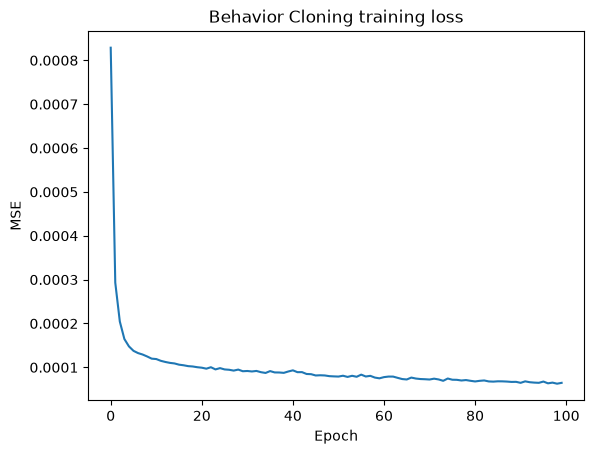

In [29]:
import matplotlib.pyplot as plt

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Behavior Cloning training loss")
plt.show()

### Policy rollout

In [30]:
def learned_policy(position, goal):
    observation = np.concatenate([position, goal])

    observation = torch.tensor(
        observation,
        dtype=torch.float32,
    )

    with torch.no_grad():
        action = policy(observation)

    return action.numpy()

In [31]:
from robot_learning_playground.point_robot import OBSTACLE 

START = np.array([0.0, 0.0])
GOAL = np.array([0.0, 1.0])

bc_trajectory = rollout(
    learned_policy,
    START,
    GOAL,
)

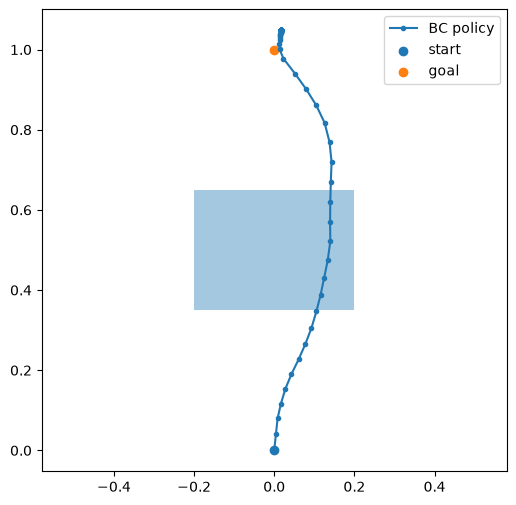

In [32]:
plt.figure(figsize=(6, 6))

positions = bc_trajectory["positions"]

plt.plot(
    positions[:, 0],
    positions[:, 1],
    "-o",
    markersize=3,
    label="BC policy",
)

rect = plt.Rectangle(
    (OBSTACLE["xmin"], OBSTACLE["ymin"]),
    OBSTACLE["xmax"] - OBSTACLE["xmin"],
    OBSTACLE["ymax"] - OBSTACLE["ymin"],
    alpha=0.4,
)

plt.gca().add_patch(rect)

plt.scatter(*START, label="start")
plt.scatter(*GOAL, label="goal")

plt.xlim(-0.6, 0.6)
plt.ylim(-0.1, 1.1)
plt.axis("equal")
plt.legend()
plt.show()

Investigate learned policy, comparing it with the expert

In [33]:
from robot_learning_playground.point_robot import left_expert, right_expert

observation = torch.tensor(
    [0.0, 0.0, 0.0, 1.0],
    dtype=torch.float32,
)

with torch.no_grad():
    predicted_action = policy(observation)

print(predicted_action)


print(
    "left: ",
    left_expert(START, GOAL),
)

print(
    "right:",
    right_expert(START, GOAL),
)

tensor([0.0043, 0.0410])
left:  [-0.02867312  0.0409616 ]
right: [0.02867312 0.0409616 ]


## Evaluating the policy over multiple rollouts

A single successful rollout does not tell us whether the learned policy is
robust.

We evaluate the policy over many randomly sampled tasks.

In [34]:
from robot_learning_playground.point_robot import sample_task

rng = np.random.default_rng(123)

trajectories = []

for _ in range(100):
    start, goal = sample_task(rng)

    trajectory = rollout(
        learned_policy,
        start,
        goal,
    )

    trajectories.append(trajectory)

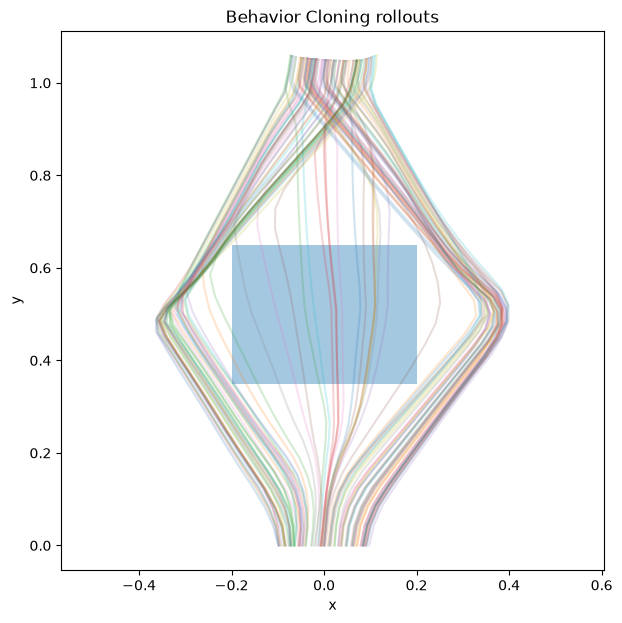

In [35]:
plt.figure(figsize=(7, 7))

for trajectory in trajectories:
    positions = trajectory["positions"]

    plt.plot(
        positions[:, 0],
        positions[:, 1],
        alpha=0.2,
    )

rect = plt.Rectangle(
    (OBSTACLE["xmin"], OBSTACLE["ymin"]),
    OBSTACLE["xmax"] - OBSTACLE["xmin"],
    OBSTACLE["ymax"] - OBSTACLE["ymin"],
    alpha=0.4,
)

plt.gca().add_patch(rect)

plt.xlim(-0.6, 0.6)
plt.ylim(-0.1, 1.1)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Behavior Cloning rollouts")
plt.axis("equal")
plt.show()

In [39]:
from robot_learning_playground.point_robot import is_collision, reached_goal

def evaluate_trajectory(trajectory, goal, tolerance=0.05):
    positions = trajectory["positions"]

    collision = any(
        is_collision(position)
        for position in positions
    )

    reached = any(
        reached_goal(position, goal, tolerance)
        for position in positions
    )

    return {
        "success": reached and not collision,
        "collision": collision,
    }

In [40]:
rng = np.random.default_rng(123)

results = []

for _ in range(100):
    start, goal = sample_task(rng)

    trajectory = rollout(
        learned_policy,
        start,
        goal,
    )

    result = evaluate_trajectory(
        trajectory,
        goal,
    )

    results.append(result)

In [41]:
success_rate = np.mean([
    r["success"] for r in results
])

collision_rate = np.mean([
    r["collision"] for r in results
])

print(f"Success rate:   {success_rate:.1%}")
print(f"Collision rate: {collision_rate:.1%}")

Success rate:   81.0%
Collision rate: 19.0%


Which function has been learned by the policy?

In [42]:
x_positions = np.linspace(-0.1, 0.1, 200)

predicted_actions = []

for x_pos in x_positions:
    position = np.array([x_pos, 0.0])
    goal = np.array([0.0, 1.0])

    action = learned_policy(position, goal)
    predicted_actions.append(action)

predicted_actions = np.asarray(predicted_actions)

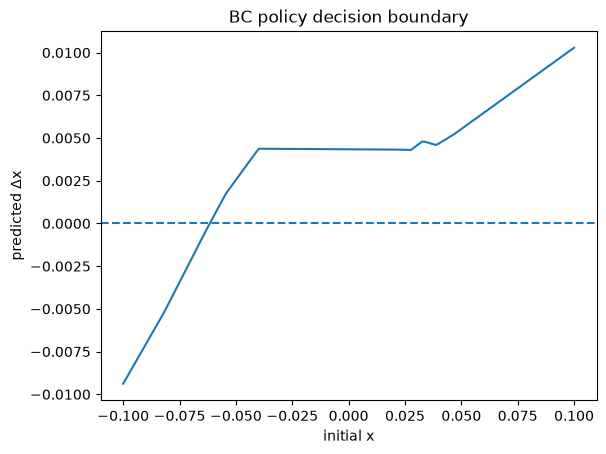

In [43]:
plt.plot(
    x_positions,
    predicted_actions[:, 0],
)

plt.axhline(0, linestyle="--")

plt.xlabel("initial x")
plt.ylabel("predicted Δx")
plt.title("BC policy decision boundary")
plt.show()